In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#Load your cleaned dataset
df = pd.read_excel("titanic_cleaned.xlsx")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (1310, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Haghish, E. F.",male,30.0000,0,0,24058,26.5500,A1 Special,S,1,NaN,"Odense, Denmark"
1,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
2,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"


In [3]:
#Check the dataset
# Dataset information
df.info()
# Statistical summary
display(df.describe(include="all").T)
# Missing values
print("\nMissing values:")
print(df.isnull().sum())
# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1310 entries, 0 to 1309
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1310 non-null   int64  
 1   survived   1310 non-null   int64  
 2   name       1310 non-null   object 
 3   sex        1310 non-null   object 
 4   age        1310 non-null   float64
 5   sibsp      1310 non-null   int64  
 6   parch      1310 non-null   int64  
 7   ticket     1310 non-null   object 
 8   fare       1310 non-null   float64
 9   cabin      296 non-null    object 
 10  embarked   1310 non-null   object 
 11  boat       487 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  746 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.4+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pclass,1310.0,NaN,NaN,NaN,2.293893,0.83828,1.0,2.0,3.0,3.0,3.0
survived,1310.0,NaN,NaN,NaN,0.382443,0.486169,0.0,0.0,0.0,1.0,1.0
name,1310,1308,"Connolly, Miss. Kate",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,1310,2,male,844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1310.0,NaN,NaN,NaN,29.503562,12.900323,0.1667,22.0,28.0,35.0,80.0
sibsp,1310.0,NaN,NaN,NaN,0.498473,1.041352,0.0,0.0,0.0,1.0,8.0
parch,1310.0,NaN,NaN,NaN,0.384733,0.865295,0.0,0.0,0.0,0.0,9.0
ticket,1310,940,CA. 2343,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fare,1310.0,NaN,NaN,NaN,33.275947,51.722067,0.0,7.8958,14.4542,31.275,512.3292
cabin,296,187,C23 C25 C27,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:
pclass          0
survived        0
name            0
sex             0
age             0
sibsp           0
parch           0
ticket          0
fare            0
cabin        1014
embarked        0
boat          823
body         1189
home.dest     564
dtype: int64

Duplicate records: 0


In [4]:
#Calculate important statistics
# 1. Overall survival statistics
print("Survival Counts:")
print(df["survived"].value_counts())
print("\nSurvival Percentages:")
print((df["survived"].value_counts(normalize=True) * 100).round(2))
# 2. Gender distribution
print("\nPassenger Count by Gender:")
print(df["sex"].value_counts())
# 3. Passenger class distribution
print("\nPassenger Count by Class:")
print(df["pclass"].value_counts().sort_index())
# 4. Age statistics
print("\nAge Statistics:")
print(df["age"].describe())
# 5. Fare statistics
print("\nFare Statistics:")
print(df["fare"].describe())

Survival Counts:
survived
0    809
1    501
Name: count, dtype: int64

Survival Percentages:
survived
0    61.76
1    38.24
Name: proportion, dtype: float64

Passenger Count by Gender:
sex
male      844
female    466
Name: count, dtype: int64

Passenger Count by Class:
pclass
1    324
2    277
3    709
Name: count, dtype: int64

Age Statistics:
count    1310.000000
mean       29.503562
std        12.900323
min         0.166700
25%        22.000000
50%        28.000000
75%        35.000000
max        80.000000
Name: age, dtype: float64

Fare Statistics:
count    1310.000000
mean       33.275947
std        51.722067
min         0.000000
25%         7.895800
50%        14.454200
75%        31.275000
max       512.329200
Name: fare, dtype: float64


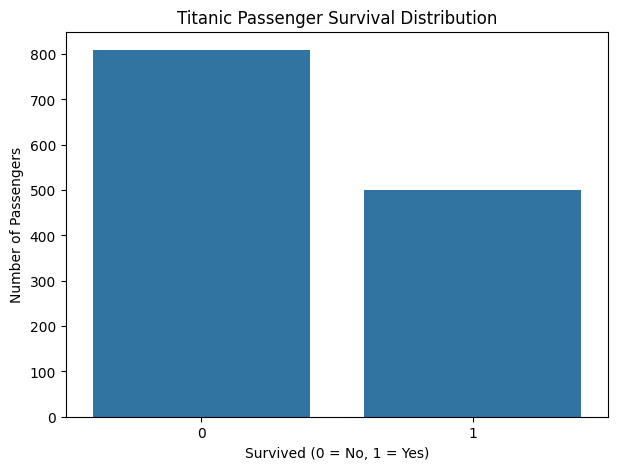

In [5]:
#Create visualizations
#Chart 1: Survival distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="survived")
plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

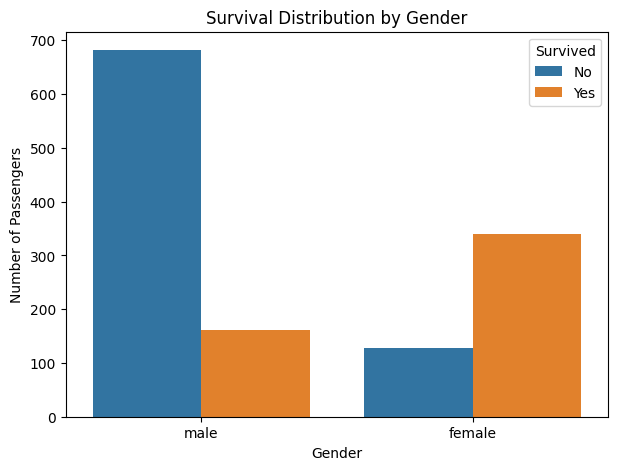

In [6]:
#Chart 2: Survival by gender
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sex", hue="survived")
plt.title("Survival Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

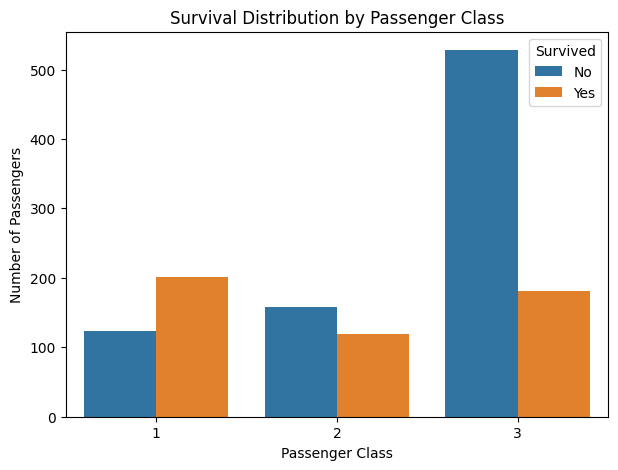

In [7]:
#Chart 3: Survival by passenger class
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="pclass", hue="survived")
plt.title("Survival Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

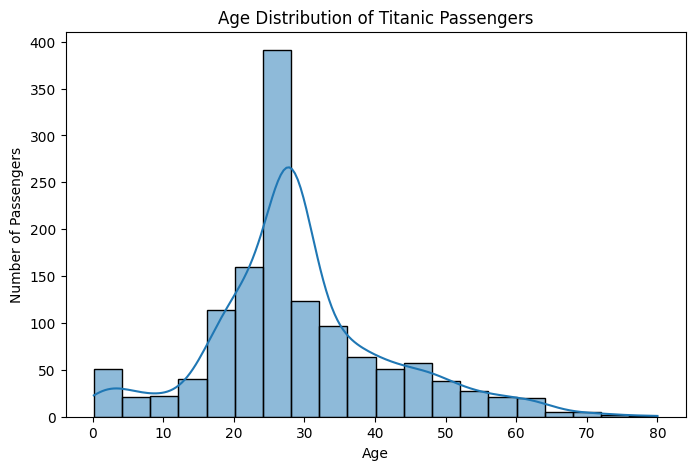

In [8]:
#Chart 4: Age distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

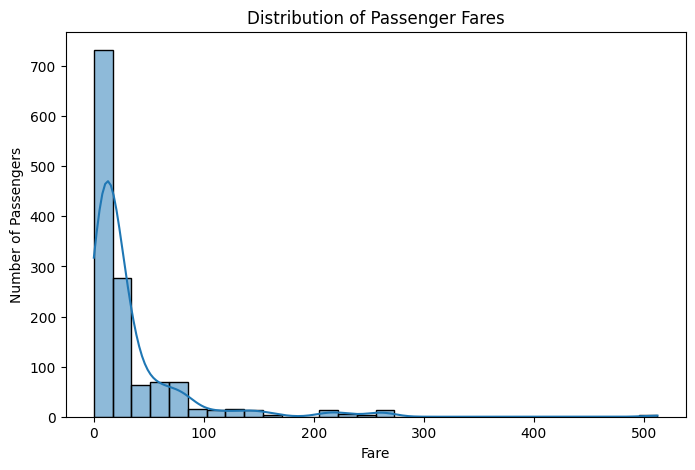

In [9]:
#Chart 5: Fare distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="fare", bins=30, kde=True)
plt.title("Distribution of Passenger Fares")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.show()

In [10]:
#Find at least five useful insights
print("Survival rate by gender (%):")
print((df.groupby("sex")["survived"].mean() * 100).round(2))
print("\nSurvival rate by passenger class (%):")
print((df.groupby("pclass")["survived"].mean() * 100).round(2))
print("\nAverage age by survival status:")
print(df.groupby("survived")["age"].mean().round(2))
print("\nAverage fare by survival status:")
print(df.groupby("survived")["fare"].mean().round(2))

Survival rate by gender (%):
sex
female    72.75
male      19.19
Name: survived, dtype: float64

Survival rate by passenger class (%):
pclass
1    62.04
2    42.96
3    25.53
Name: survived, dtype: float64

Average age by survival status:
survived
0    29.95
1    28.79
Name: age, dtype: float64

Average fare by survival status:
survived
0    23.34
1    49.32
Name: fare, dtype: float64


In [11]:
#Calculate and display five insights
# 1. Overall survival rate
survival_rate = df["survived"].mean() * 100
print(f"Overall survival rate: {survival_rate:.2f}%")
# 2. Survival rate by gender
gender_survival = (
    df.groupby("sex")["survived"].mean() * 100
).round(2)
print("\nSurvival rate by gender:")
print(gender_survival)
# 3. Survival rate by passenger class
class_survival = (
    df.groupby("pclass")["survived"].mean() * 100
).round(2)
print("\nSurvival rate by passenger class:")
print(class_survival)
# 4. Average age by survival status
age_survival = df.groupby("survived")["age"].mean().round(2)
print("\nAverage age by survival status (0 = No, 1 = Yes):")
print(age_survival)
# 5. Average fare by survival status
fare_survival = df.groupby("survived")["fare"].mean().round(2)
print("\nAverage fare by survival status (0 = No, 1 = Yes):")
print(fare_survival)

Overall survival rate: 38.24%

Survival rate by gender:
sex
female    72.75
male      19.19
Name: survived, dtype: float64

Survival rate by passenger class:
pclass
1    62.04
2    42.96
3    25.53
Name: survived, dtype: float64

Average age by survival status (0 = No, 1 = Yes):
survived
0    29.95
1    28.79
Name: age, dtype: float64

Average fare by survival status (0 = No, 1 = Yes):
survived
0    23.34
1    49.32
Name: fare, dtype: float64


***Exploratory Data Analysis — Key Findings***

**1. Overall Survival Rate**

The overall survival rate was 38.24%, meaning that fewer than half of the passengers in the analyzed dataset survived.

**2. Gender-Based Survival**

Female passengers had a survival rate of 72.75%, compared with 19.19% for male passengers. This represents a substantial difference in survival outcomes by gender.

**3. Passenger Class and Survival**

First-class passengers recorded the highest survival rate at 62.04%. Second-class passengers had a rate of 42.96%, while third-class passengers had the lowest rate at 25.53%. This pattern indicates an association between passenger class and survival.

**4. Age and Survival**

The average age of survivors was 28.79 years, compared with 29.95 years among non-survivors. The difference was relatively small, suggesting that average age alone does not fully describe survival outcomes.

**5. Fare and Survival**

Survivors paid an average fare of 49.32, whereas non-survivors paid an average fare of 23.34. This suggests an association between fare and survival, potentially reflecting differences in passenger class and other factors.

**Conclusion**

The analysis identified meaningful patterns in passenger survival by gender, class, age, and fare. These findings demonstrate how descriptive statistics and visualizations can help uncover trends and support further data analysis. The results show associations rather than proof of causation.

**Note:** Missing age and fare values were imputed during the data-cleaning stage. These preprocessing decisions should be considered when interpreting the results.